# ANÁLISIS EXPLORATORIO DATOS REGISTRO ACTIVOS GENERACIÓN - REPORTE AGOSTO 2026

# Documentación de la base da datos:

https://www.upme.gov.co/simec/energia-electrica/generacion-de-energia-electrica/registro-de-proyectos-de-generacion/
    
Se realizó la extracción del informe registros activos de proyectos de generación eléctrica desde la página web de la Unidad de Planeación Minero Energética (UPME).

La captura de la información se llevó a cabo mediante la descarga del archivo directo en formato xlsx.

## Ficha Técnica de Extracción

**Fuente de datos:** Website UPME (Unidad de Planeación Minero Energética)

**Método de adquisición:** Descarga directa archivo xlsx

**Fecha Descarga:** 04/10/2026

**Variables principales:** 'Codigo Proyecto','Nombre  del proyecto', 'Estado', 'Recurso ', 'Tipo', 'Tecnología','Capacidad [MW]', 'Departamento', 'Municipio','Fecha de inicio de construcción', 'Fecha de entrada en operación'.


In [104]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go

import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

df= pd.read_excel('Informe_registros_activos_de_proyectos_generacion_electrica_agosto_2026.xlsx',header=2)

### 1. Limpieza e Inspección Inicial Datos

In [105]:
df.head()

,Unnamed: 0,Codigo Proyecto,Marco normativo \naplicable,Fecha Inscripción proyecto,Fecha límite de validez,Nombre del proyecto,Estado,Recurso,Tipo,Tecnología,Capacidad [MW],Departamento,Municipio,Fecha de inicio de construcción,Fecha de entrada en operación,Columna1,Columna2,Columna3,Columna4,Columna5
0,NaN,1581,Resolución UPME No. 749 de 2025,2026-08-21,2027-01-01,PARQUE DE GENERACIÓN FOTOVOLTAICO LA PRIMAVERA...,FASE 1,SOLAR,SOL,FOTOVOLTAICO,57.00,CAQUETÁ,EL DONCELLO,2027-01-01,2027-07-31,YOPAL,2027-12-31,2028-12-31,NaN,2032.0
1,NaN,1303,Resolución UPME No. 749 de 2025,2026-08-20,2028-08-19,PCH SALITRE,FASE 2,HIDRÁULICO,AGUA,FILO DE AGUA,16.49,SANTANDER,PUENTE NACIONAL,2030-09-02,2032-11-30,NEIVA,2026-10-30,2027-03-01,NaN,NaN
2,NaN,1304,Resolución UPME No. 749 de 2025,2026-08-20,2028-08-19,PCH PLANADA,FASE 2,HIDRÁULICO,AGUA,FILO DE AGUA,19.90,SANTANDER,PUENTE NACIONAL,2030-06-05,2032-12-31,MORALES,2026-09-01,2027-03-01,NaN,2033.0
3,NaN,1305,Resolución UPME No. 749 de 2025,2026-08-20,2028-08-19,PCH PALMAR,FASE 2,HIDRÁULICO,AGUA,FILO DE AGUA,19.49,SANTANDER,PUENTE NACIONAL,2030-09-02,2032-11-30,ZONA BANANERA,2027-01-31,2027-12-31,NaN,NaN
4,NaN,3894,Resolución UPME No. 749 de 2025,2026-08-05,2027-01-01,PARQUE DE GENERACIÓN FOTOVOLTAICO TESALIA DE 8...,FASE 1,SOLAR,SOL,FOTOVOLTAICO,80.00,HUILA,TESALIA,2027-01-01,2028-01-01,SALGAR,2027-01-01,2028-12-31,NaN,2027.0


In [106]:
df.columns

Index(['Unnamed: 0', 'Codigo Proyecto', 'Marco normativo \naplicable',
       'Fecha Inscripción proyecto', 'Fecha límite de validez',
       'Nombre  del proyecto', 'Estado', 'Recurso ', 'Tipo', 'Tecnología',
       'Capacidad [MW]', 'Departamento', 'Municipio',
       'Fecha de inicio de construcción', 'Fecha de entrada en operación',
       'Columna1', 'Columna2', 'Columna3', 'Columna4', 'Columna5'],
      dtype='object')

Revisamos detalladamente la información contenida en el archivo base con el objetivo de identificar la validez de aquellos campos sin datos o con datos de baja completitud, detectando que las mismas pueden eliminarse sin perdida de información de análisis. Se renombra variable 'Marco normativo \naplicable'.

In [107]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56 entries, 0 to 55
Data columns (total 20 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   Unnamed: 0                       0 non-null      float64       
 1   Codigo Proyecto                  56 non-null     int64         
 2   Marco normativo 
aplicable       55 non-null     object        
 3   Fecha Inscripción proyecto       55 non-null     datetime64[ns]
 4   Fecha límite de validez          55 non-null     datetime64[ns]
 5   Nombre  del proyecto             55 non-null     object        
 6   Estado                           55 non-null     object        
 7   Recurso                          55 non-null     object        
 8   Tipo                             55 non-null     object        
 9   Tecnología                       55 non-null     object        
 10  Capacidad [MW]                   56 non-null     float64       


In [108]:
df=df.drop(columns=['Unnamed: 0','Columna1', 'Columna2', 'Columna3', 'Columna4', 'Columna5'],axis=1)
df=df.rename(columns={'Marco normativo \naplicable': 'Marco normativo aplicable','Recurso ':'Recurso'})

In [109]:
df.describe()

,Codigo Proyecto,Capacidad [MW]
count,56.000000,56.000000
mean,3303.500000,186.083143
std,1089.958548,695.320590
min,55.000000,0.148000
25%,3618.000000,19.900000
50%,3846.500000,53.500000
75%,3875.250000,138.750000
max,3894.000000,5210.328000


In [110]:
# 1. Ver todos los valores únicos reales en la columna 'Recurso' (incluyendo espacios o textos raros)
print("Valores únicos en Recurso:")
print(df["Recurso"].value_counts(dropna=False))

# 2. Filtrar y mostrar las filas que NO son ninguna de las 4 tecnologías principales
recursos_esperados = ["SOLAR", "EÓLICO", "HIDRÁULICO", "TÉRMICO"]

# Normalizamos a mayúsculas y quitamos espacios para comparar bien
df_desconocidos = df[
    ~df["Recurso"].astype(str).str.strip().str.upper().isin(recursos_esperados)
]

print(f"\nTotal de filas con recursos extraños o vacíos: {len(df_desconocidos)}")
print(
    f"Capacidad acumulada de estas filas: {df_desconocidos['Capacidad [MW]'].sum()} MW"
)

# Mostrar la tabla con estas filas para identificarlas
display(df_desconocidos)

Valores únicos en Recurso:
SOLAR          30
HIDRÁULICO     14
EÓLICO          4
HIDRÁULICO      3
SOLAR           2
TÉRMICO         2
NaN             1
Name: Recurso, dtype: int64

Total de filas con recursos extraños o vacíos: 1
Capacidad acumulada de estas filas: 5210.327999999999 MW


,Codigo Proyecto,Marco normativo aplicable,Fecha Inscripción proyecto,Fecha límite de validez,Nombre del proyecto,Estado,Recurso,Tipo,Tecnología,Capacidad [MW],Departamento,Municipio,Fecha de inicio de construcción,Fecha de entrada en operación
55,55,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,5210.328,NaN,NaN,NaT,NaT


Durante la revisión de la información consolidada, se identifica que este recurso corresponde realmente a la sumatoria de la capacidad proyectada en construcción. Por lo cual procedemos a remover esta fila para nuestro análisis.

In [111]:
recursos_validos = ["SOLAR", "EÓLICO", "HIDRÁULICO", "TÉRMICO"]

# Filtrar el DataFrame para conservar ÚNICAMENTE las filas con recursos válidos
# (Esto elimina automáticamente cualquier espacio en blanco, NaN o texto extraño)
df = df[df["Recurso"].astype(str).str.strip().str.upper().isin(recursos_validos)]

print("En el periodo 2027 a 2033, se proyecta una capacidad adicional de generación de:",df['Capacidad [MW]'].sum(),"MW")

En el periodo 2027 a 2033, se proyecta una capacidad adicional de generación de: 5210.3279999999995 MW


In [122]:
df.head(2)

,Codigo Proyecto,Marco normativo aplicable,Fecha Inscripción proyecto,Fecha límite de validez,Nombre del proyecto,Estado,Recurso,Tipo,Tecnología,Capacidad [MW],Departamento,Municipio,Fecha de inicio de construcción,Fecha de entrada en operación,Año de Entrada en Operación,Año de inicio de construcción,Tiempo de construcción (días),latitud,longitud
0,1581,Resolución UPME No. 749 de 2025,2026-08-21,2027-01-01,PARQUE DE GENERACIÓN FOTOVOLTAICO LA PRIMAVERA...,FASE 1,SOLAR,SOL,FOTOVOLTAICO,57.00,CAQUETÁ,EL DONCELLO,2027-01-01,2027-07-31,2027,2027,211,1.3361,-75.2789
1,1303,Resolución UPME No. 749 de 2025,2026-08-20,2028-08-19,PCH SALITRE,FASE 2,HIDRÁULICO,AGUA,FILO DE AGUA,16.49,SANTANDER,PUENTE NACIONAL,2030-09-02,2032-11-30,2032,2030,820,5.8756,-73.6739


In [123]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 55 entries, 0 to 54
Data columns (total 19 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   Codigo Proyecto                  55 non-null     int64         
 1   Marco normativo aplicable        55 non-null     object        
 2   Fecha Inscripción proyecto       55 non-null     datetime64[ns]
 3   Fecha límite de validez          55 non-null     datetime64[ns]
 4   Nombre  del proyecto             55 non-null     object        
 5   Estado                           55 non-null     object        
 6   Recurso                          55 non-null     object        
 7   Tipo                             55 non-null     object        
 8   Tecnología                       55 non-null     object        
 9   Capacidad [MW]                   55 non-null     float64       
 10  Departamento                     55 non-null     object        


In [124]:
# Se realiza corrección sobre nombres con espacios en campo Departamento.

df.Departamento=df.Departamento.str.strip()
df.Recurso=df.Recurso.str.strip()

### 2. Enriquecimiento de datos

In [114]:
# Incluimos el año de entrada en Operación y año inicio construcción, así como el cálculo del tiempo de construcción.

df['Año de Entrada en Operación'] = df['Fecha de entrada en operación'].dt.year.astype('Int64')
df['Año de inicio de construcción'] = df['Fecha de inicio de construcción'].dt.year.astype('Int64')
df['Tiempo de construcción (días)'] =(df['Fecha de entrada en operación']- df['Fecha de inicio de construcción']).dt.days

In [115]:
# 1. Diccionario con las coordenadas exactas para los municipios
coordenadas_municipios = {
    ("CAQUETÁ", "EL DONCELLO"): {"latitud": 1.3361, "longitud": -75.2789},
    ("SANTANDER", "PUENTE NACIONAL"): {"latitud": 5.8756, "longitud": -73.6739},
    ("HUILA", "TESALIA"): {"latitud": 2.4172, "longitud": -75.7533},
    ("ANTIOQUIA", "YOLOMBO"): {"latitud": 6.5744, "longitud": -75.0136},
    ("CESAR", "BOSCONIA"): {"latitud": 9.9656, "longitud": -73.8883},
    ("CALDAS", "CHINCHINA"): {"latitud": 4.9606, "longitud": -75.5975},
    ("HUILA", "VILLAVIEJA"): {"latitud": 3.2208, "longitud": -75.2189},
    ("ANTIOQUIA", "CAROLINA"): {"latitud": 6.7214, "longitud": -75.3183},
    ("ANTIOQUIA", "REMEDIOS"): {"latitud": 7.0267, "longitud": -74.6853},
    ("CASANARE", "YOPAL"): {"latitud": 5.3378, "longitud": -72.3958},
    ("HUILA", "NEIVA"): {"latitud": 2.9273, "longitud": -75.2819},
    ("CAUCA", "MORALES"): {"latitud": 2.7744, "longitud": -76.6231},
    ("MAGDALENA", "ZONA BANANERA"): {"latitud": 10.7725, "longitud": -74.1200},
    ("ANTIOQUIA", "CIUDAD BOLIVAR"): {"latitud": 5.7583, "longitud": -76.0142},
    ("ANTIOQUIA", "SALGAR"): {"latitud": 5.9650, "longitud": -75.9619},
    ("CORDOBA", "PUEBLO NUEVO"): {"latitud": 8.0675, "longitud": -75.5414},
    ("BOYACA", "SAN MIGUEL DE SEMA"): {"latitud": 5.4853, "longitud": -73.7431},
    ("CUNDINAMARCA", "MOSQUERA"): {"latitud": 4.7078, "longitud": -74.2306},
    ("SANTANDER", "LOS SANTOS"): {"latitud": 6.8372, "longitud": -73.1164},
    ("LA GUAJIRA", "SAN JUAN DEL CESAR"): {
        "latitud": 10.3756,
        "longitud": -73.0075,
    },
    ("CORDOBA", "CHINU"): {"latitud": 9.1436, "longitud": -75.3850},
    ("BOYACA", "PUERTO BOYACA"): {"latitud": 5.9725, "longitud": -74.5878},
    ("META", "VILLAVICENCIO"): {"latitud": 4.1420, "longitud": -73.6266},
    ("CORDOBA", "MONTELIBANO"): {"latitud": 7.9786, "longitud": -75.4058},
    ("TOLIMA", "FLANDES"): {"latitud": 4.2964, "longitud": -74.8144},
    ("HUILA", "HOBO"): {"latitud": 2.5694, "longitud": -75.5444},
    ("HUILA", "ALTAMIRA"): {"latitud": 2.0628, "longitud": -75.7667},
    ("HUILA", "PALERMO"): {"latitud": 2.8422, "longitud": -75.4339},
    ("MAGDALENA", "SITIONUEVO"): {"latitud": 10.7831, "longitud": -74.7214},
    ("CESAR", "VALLEDUPAR"): {"latitud": 10.4631, "longitud": -73.2532},
    ("CORDOBA", "SAHAGUN"): {"latitud": 8.9419, "longitud": -75.4467},
    ("ANTIOQUIA", "FRONTINO"): {"latitud": 6.7797, "longitud": -76.1239},
    ("SANTANDER", "BARRANCABERMEJA"): {"latitud": 7.0653, "longitud": -73.8547},
    ("CALDAS", "AGUADAS"): {"latitud": 5.6128, "longitud": -75.4619},
    ("ANTIOQUIA", "SONSON"): {"latitud": 5.7114, "longitud": -75.3117},
    ("RISARALDA", "PUEBLO RICO"): {"latitud": 5.2289, "longitud": -76.0350},
    ("ANTIOQUIA", "HISPANIA"): {"latitud": 5.7958, "longitud": -76.0744},
    ("NORTE DE SANTANDER", "LA ESPERANZA"): {
        "latitud": 8.2325,
        "longitud": -73.5939,
    },
    ("BOYACA", "PAEZ"): {"latitud": 4.5422, "longitud": -73.2189},
    ("BOYACA", "MIRAFLORES"): {"latitud": 5.2017, "longitud": -73.1417},
    ("ATLANTICO", "TUBARA"): {"latitud": 10.8717, "longitud": -74.9806},
    ("BOLIVAR", "SANTA CATALINA"): {"latitud": 10.6019, "longitud": -75.2819},
    ("ARAUCA", "TAME"): {"latitud": 6.4528, "longitud": -71.7428},
    ("ARAUCA", "ARAUCA"): {"latitud": 7.0847, "longitud": -70.7591},
    ("SANTANDER", "PUERTO WILCHES"): {"latitud": 7.3347, "longitud": -73.9056},
}

# 2. Convertir el diccionario a DataFrame auxiliar
df_coords = pd.DataFrame.from_dict(
    coordenadas_municipios, orient="index"
).reset_index()
df_coords.columns = ["departamento_key", "municipio_key", "latitud", "longitud"]

# 3. Normalizar columnas en tu dataset principal (reemplaza 'df' y los nombres reales de tus columnas si difieren)
# Esto limpia espacios y convierte a mayúsculas para que el cruce sea exacto
df["departamento_key"] = (
    df["Departamento"].astype(str).str.strip().str.upper()
)
df["municipio_key"] = df["Municipio"].astype(str).str.strip().str.upper()

# 4. Hacer el cruce (merge) por departamento y municipio
df = pd.merge(df, df_coords, on=["departamento_key", "municipio_key"], how="left")

# 5. Limpiar las columnas auxiliares temporales
df = df.drop(columns=["departamento_key", "municipio_key"])

# Ver las primeras filas con las nuevas columnas de coordenadas
display(df.head(2))

,Codigo Proyecto,Marco normativo aplicable,Fecha Inscripción proyecto,Fecha límite de validez,Nombre del proyecto,Estado,Recurso,Tipo,Tecnología,Capacidad [MW],Departamento,Municipio,Fecha de inicio de construcción,Fecha de entrada en operación,Año de Entrada en Operación,Año de inicio de construcción,Tiempo de construcción (días),latitud,longitud
0,1581,Resolución UPME No. 749 de 2025,2026-08-21,2027-01-01,PARQUE DE GENERACIÓN FOTOVOLTAICO LA PRIMAVERA...,FASE 1,SOLAR,SOL,FOTOVOLTAICO,57.00,CAQUETÁ,EL DONCELLO,2027-01-01,2027-07-31,2027,2027,211,1.3361,-75.2789
1,1303,Resolución UPME No. 749 de 2025,2026-08-20,2028-08-19,PCH SALITRE,FASE 2,HIDRÁULICO,AGUA,FILO DE AGUA,16.49,SANTANDER,PUENTE NACIONAL,2030-09-02,2032-11-30,2032,2030,820,5.8756,-73.6739


### 3. Análisis de datos

In [116]:
df.groupby(['Año de Entrada en Operación'])['Capacidad [MW]'].agg(['sum','min','max','mean'])

,sum,min,max,mean
Año de Entrada en Operación,,,,
2027,876.548,0.148,350.0,67.426769
2028,1079.790,4.990,200.0,107.979000
2029,2685.170,5.400,800.0,127.865238
2030,133.140,19.900,80.0,44.380000
2031,49.900,49.900,49.9,49.900000
2032,185.780,16.000,94.0,30.963333
2033,200.000,200.000,200.0,200.000000


El sistema de generación colombiano, mantiene su proyección de expansión con un nuevo máximo de crecimiento proyectado para el año 2029, con adición de 2685MW de capacidad al SIN.

In [117]:
# 1. Generar la tabla de agregación original
df_agg = (
    df.groupby(["Recurso"])["Capacidad [MW]"]
    .agg(["sum", "min", "max", "mean"])
    .sort_values(by="sum", ascending=False)
)

# 2. Crear una nueva columna con el porcentaje de participación de la suma respecto al total general
df_agg["sum_%"] = (df_agg["sum"] / df_agg["sum"].sum()) * 100

# Opcional: Redondear a 2 decimales para mayor legibilidad
df_agg = df_agg.round(2)

display(df_agg)

,sum,min,max,mean,sum_%
Recurso,,,,,
SOLAR,3870.88,4.99,800.0,120.96,74.29
EÓLICO,590.00,90.00,200.0,147.50,11.32
HIDRÁULICO,507.45,0.15,94.0,29.85,9.74
TÉRMICO,242.00,42.00,200.0,121.00,4.64


In [118]:
df.groupby(['Departamento'])['Capacidad [MW]'].agg(['sum']).reset_index().sort_values(by='sum', ascending = False).head(10)

,Departamento,sum
10,CORDOBA,1460.00
9,CESAR,900.00
12,HUILA,579.70
4,BOYACA,346.14
0,ANTIOQUIA,270.21
15,META,269.90
2,ATLANTICO,240.00
18,SANTANDER,215.78
3,BOLIVAR,200.00
13,LA GUAJIRA,159.90


Los nuevos proyectos de generación se concentran en la zona caribe con alta influencia de departamentos como Cordoba y Cesar. Se mantiene la macrotendencia de implementación de recurso Solar con un 74% del total de la generación en construcción, y la entrada en operación de proyectos Eólicos con 11% de la capacidad en construcción.

In [119]:
# Asegurar que los nombres de los recursos coincidan exactamente con los valores de tu DataFrame
fig = px.bar(
    df,
    x="Año de Entrada en Operación",
    y="Capacidad [MW]",
    color="Recurso",
    hover_data=["Departamento",'Tecnología'], 
    color_discrete_map={
        'SOLAR': '#f0ad4e',       # Naranja solar brillante (Focal)
        'TÉRMICO': '#d9534f',     # Rojo/Rosado térmico
        'TÉRMICA': '#d9534f',
        'HIDRÁULICO': '#6c8ebf',  # Azul hidráulico
        'HIDRÁULICA': '#6c8ebf',
        'EÓLICO': '#5cb85c',      # Verde eólico
        'EÓLICA': '#5cb85c',
        'COGENERADOR': '#b0b1b2'  # Gris neutro
    },
    title=(
        "<b>El pipeline de expansión proyecta un pico histórico de entrada solar para 2029, superando los 2,600 MW</b><br>"
        "<sup>Capacidad total proyectada (MW) por año de entrada en operación y recurso tecnológico (2027-2033)</sup>"
    ),
    barmode="stack",
    height=550,
    template="plotly_white"
)

# Actualizar ejes, títulos y corregir el título de la leyenda
fig.update_layout(
    xaxis_title="Año de Entrada en Operación Proyectado",
    yaxis_title="Capacidad Total Proyectada [MW]",
    legend_title="Recurso / Tecnología",  # Corregido de "Departamento" a "Recurso / Tecnología"
    title_font=dict(size=14, color='#222222'),
    font=dict(family="Arial, sans-serif", size=12),
    margin=dict(t=80, r=20, l=60, b=50)
)

fig.show()

La expansión del sistema con uso predominante solar se mantiene, se observa la inclusión de plantas solares de mayor tamaño: 800MW en Cesar y 400MW Cordoba, Antioquia mantiene su apuesta por el recurso hídrico sin embargo con proyectos de menor escala al histórico (Filo de Agua). Se proyecta para 2029 el ingreso de potencia eólica con 150MW en Atlantico, 90MW en La Guajira y 2033 200MW en Bolivar (Proyecto Costa Afuera).

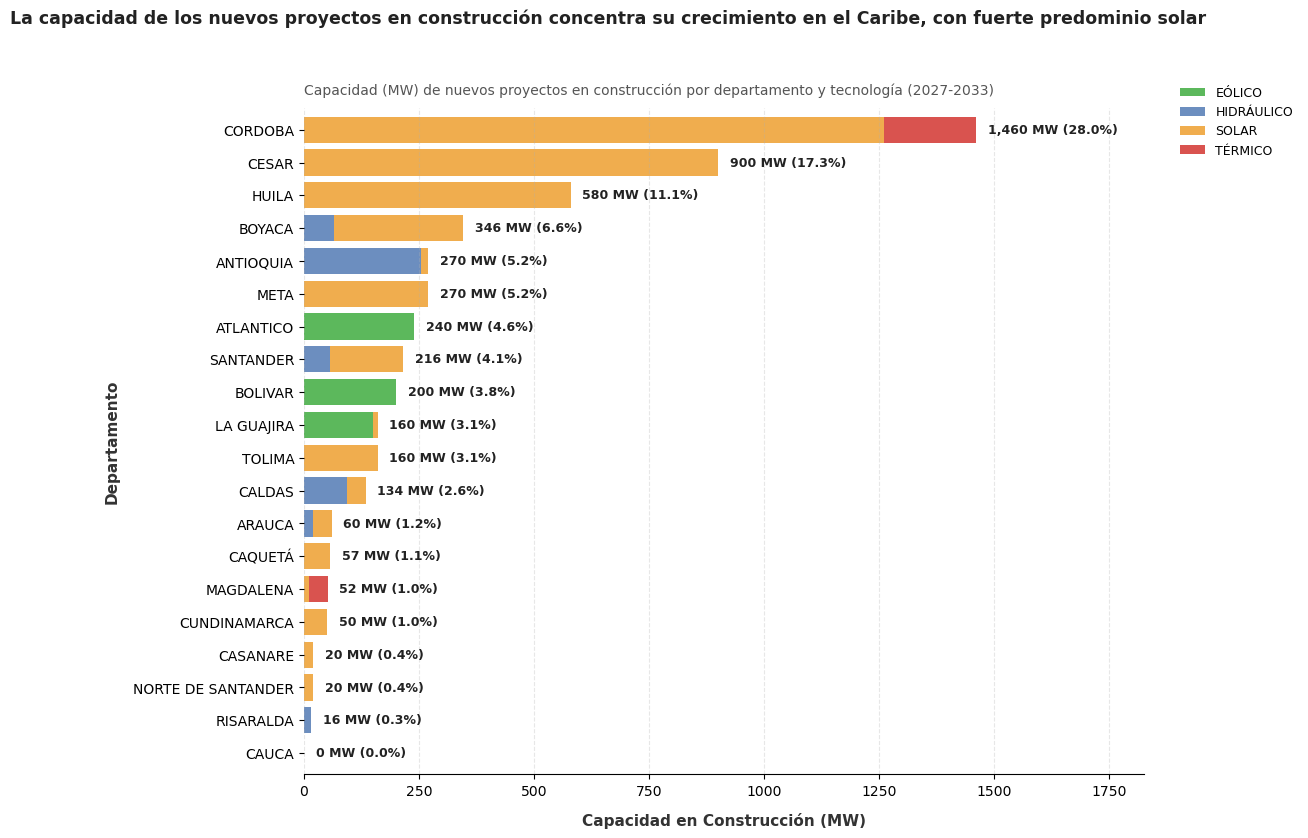

In [120]:
# 1. Agrupar por departamento y tipo de generación (Proyectos en construcción 2027-2033)
df_tipo = (
    df.groupby(["Departamento", "Recurso"])["Capacidad [MW]"]
    .sum()
    .unstack(fill_value=0)
)

# 2. Ordenar departamentos por capacidad total descendente
df_tipo['TOTAL_Mw'] = df_tipo.sum(axis=1)
df_tipo = df_tipo.sort_values(by='TOTAL_Mw', ascending=False)

totales = df_tipo['TOTAL_Mw']
df_plot = df_tipo.drop(columns=['TOTAL_Mw'])

# 3. Mapeo de colores semántico y limpio
colores_tipo = {
    'SOLAR': '#f0ad4e',       # Naranja solar brillante (Focal)
    'TÉRMICO': '#d9534f',     # Rojo/Rosado térmico
    'TÉRMICA': '#d9534f',
    'HIDRÁULICO': '#6c8ebf',  # Azul hidráulico
    'HIDRÁULICA': '#6c8ebf',
    'EÓLICO': '#5cb85c',      # Verde eólico
    'EÓLICA': '#5cb85c',
    'COGENERADOR': '#b0b1b2'  # Gris neutro
}

colors_presentes = [colores_tipo.get(col, '#d3d3d3') for col in df_plot.columns]

total_nacional = totales.sum()
pct_global = (totales / total_nacional) * 100

# 4. Crear figura con márgenes optimizados para evitar apiñamiento en la esquina superior derecha
fig, ax = plt.subplots(figsize=(14, 9))
fig.subplots_adjust(top=0.85, right=0.82, left=0.22)  # right=0.82 aleja la leyenda del borde

# Graficar barras horizontales apiladas
df_plot.plot(
    kind='barh', 
    stacked=True, 
    ax=ax, 
    color=colors_presentes, 
    width=0.8,
    linewidth=0
)

ax.invert_yaxis()  # Mantener el departamento con mayor capacidad en construcción arriba

# 5. Etiquetas de total y porcentaje al final de cada barra
for i, (dept, total_mw) in enumerate(totales.items()):
    pct = pct_global[dept]
    ax.text(
        total_mw + 25, i, 
        f'{total_mw:,.0f} MW ({pct:.1f}%)', 
        va='center', ha='left', 
        fontsize=9, fontweight='bold', color='#222222'
    )

# 6. Título principal de acción y subtítulo
plt.suptitle(
    "La capacidad de los nuevos proyectos en construcción concentra su crecimiento en el Caribe, con fuerte predominio solar", 
    x=0.01, y=0.96, ha='left', fontsize=12.5, fontweight='bold', color='#222222'
)
plt.title(
    "Capacidad (MW) de nuevos proyectos en construcción por departamento y tecnología (2027-2033)", 
    loc='left', fontsize=10, color='#555555', pad=10
)

# 7. Leyenda reubicada holgadamente a la derecha
ax.legend(
    title='', 
    bbox_to_anchor=(1.03, 1.05), 
    loc='upper left', 
    ncol=1, 
    frameon=False, 
    fontsize=9
)

# 8. Formato de ejes y estilo visual
plt.xlabel('Capacidad en Construcción (MW)', fontsize=11, labelpad=10, fontweight='bold', color='#333333')
plt.ylabel('Departamento', fontsize=11, labelpad=10, fontweight='bold', color='#333333')
plt.xlim(0, totales.max() * 1.25)

sns.despine(left=True)
plt.grid(axis='x', linestyle='--', alpha=0.3)

plt.show()

En términos generales, los proyectos de generación que aportarán la mayor potencial adicional al SIN, se concentran en Cordoba, Cesar y Huila, estos aportan el 56% del crecimiento previsto en el periodo 2027 a 2033. Se denota positivamente el esfuerzo nacional en la diversificación del sistema, apostando por proyectos, a filo de agua y eólicos en su plan de expansión.

In [121]:
# 1. Preparar datos para el mapa
df_mapa = df.copy()

# 2. Crear mapa de burbujas interactivo con Plotly Express
fig = px.scatter_mapbox(
    df_mapa,
    lat='latitud',
    lon='longitud',
    size='Capacidad [MW]',
    color='Recurso',
    hover_name='Municipio',
    hover_data={
        'Departamento': True,
        'Capacidad [MW]': ':.1f',  # Formato numérico flotante a 1 decimal
        'latitud': False,
        'longitud': False,
    },
    labels={
        'Recurso': 'Tecnología'
    },
    color_discrete_map={
    'SOLAR': '#f0ad4e',       # Naranja solar brillante (Focal)
    'TÉRMICO': '#d9534f',     # Rojo/Rosado térmico
    'TÉRMICA': '#d9534f',
    'HIDRÁULICO': '#6c8ebf',  # Azul hidráulico
    'HIDRÁULICA': '#6c8ebf',
    'EÓLICO': '#5cb85c',      # Verde eólico
    'EÓLICA': '#5cb85c',
    'COGENERADOR': '#b0b1b2'  # Gris neutro
    },
    size_max=35,
    zoom=5.1,  # Zoom ligeramente más cercano para destacar el territorio nacional
    center={"lat": 4.5709, "lon": -74.2973},  # Centro geográfico de Colombia
    mapbox_style="carto-positron",
    title="<b>La nueva capacidad de generación en ejecución prioriza la tecnología solar fotovoltaica en el norte del país</b><br><sup>Mapa de distribución geográfica de proyectos en construcción (2027–2033) y capacidad (MW) en el SIN</sup>"
)

# 3. Ajustes finos de diseño y layout
fig.update_layout(
    margin={"r": 0, "t": 60, "l": 0, "b": 0},
    legend_title_text='Tecnología',
    font=dict(family="Arial, sans-serif", size=12),
    title_font=dict(size=14, color='#222222'),
)

fig.show()

El SIN mantiene la apuesta en la zona caribe con tecnología solar, sin embargo, el valle interandino proyecta un crecimiento interesante de proyectos solares de menor escala que permiten diversificar la generación regional que históricamente se ha constituido con base en recurso hídrico, un interesante ejercicio de análisis posterior consiste en incluir gráficamente tanto los proyectos actuales como los proyectos en construcción, para entender potenciales cambios en los focos regionales de generación.